<a href="https://colab.research.google.com/github/alamgircanb/Business-Analysis-Data-Analytics-Intelligence/blob/main/06_Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6. Introduction to Deep Learning (Enhanced)

This notebook provides an enhanced and more detailed introduction to **Deep Learning**, a powerful subfield of machine learning inspired by the structure and function of the human brain. We will explore the fundamental concepts of neural networks, build and train a simple deep learning model using Keras, and understand key aspects of its training and evaluation.

**What is Deep Learning?**
Deep learning utilizes artificial neural networks with multiple layers (hence "deep") to learn complex patterns and representations directly from raw data. Unlike traditional machine learning, which often requires extensive manual feature engineering, deep learning models can automatically discover intricate features from large datasets.

**Why the Resurgence of Deep Learning?**
-   **Big Data:** The availability of vast amounts of data (images, text, audio) for training.
-   **Computational Power:** Advances in hardware, particularly GPUs (Graphics Processing Units), which are highly efficient for parallel computations required by neural networks.
-   **Algorithmic Innovations:** Development of new network architectures (e.g., CNNs, RNNs, Transformers) and improved optimization techniques (e.g., Adam optimizer, ReLU activation, Dropout).
-   **Open-Source Frameworks:** User-friendly libraries like TensorFlow and PyTorch have made deep learning more accessible.

**Core Components of a Neural Network:**
-   **Neurons (Nodes):** Basic computational units that receive inputs, apply a weighted sum, pass it through an activation function, and produce an output.
-   **Layers:**
    -   **Input Layer:** Receives the raw data.
    -   **Hidden Layers:** One or more layers between the input and output layers where the network learns complex representations.
    -   **Output Layer:** Produces the final prediction.
-   **Weights and Biases:** Parameters that the network learns during training, representing the strength of connections between neurons.
-   **Activation Functions:** Introduce non-linearity into the network, allowing it to learn non-linear relationships in the data. Common examples include ReLU, Sigmoid, and Softmax.

We will build a simple neural network to classify images of handwritten digits from the famous **MNIST dataset**, a common "hello world" for deep learning.

### Step 1: Import Libraries

We'll use TensorFlow and its high-level API, Keras, for building and training our neural network. Matplotlib and NumPy will be used for data handling and visualization.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.figsize'] = (10, 7) # Set default figure size

### Step 2: Load and Prepare the MNIST Dataset

The MNIST dataset consists of 60,000 training images and 10,000 testing images of handwritten digits (0-9). Each image is a 28x28 pixel grayscale image. We need to normalize the pixel values and potentially reshape the data for our neural network.

In [ ]:
# Load the dataset
mnist = keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print(f"Training data shape: {X_train.shape}") # (60000, 28, 28)
print(f"Training labels shape: {y_train.shape}") # (60000,)
print(f"Test data shape: {X_test.shape}") # (10000, 28, 28)
print(f"Test labels shape: {y_test.shape}") # (10000,)

# Normalize the pixel values to be between 0 and 1
# Pixel values range from 0 to 255. Dividing by 255 scales them.
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Pixel values normalized.")

Training data shape: (60000, 28, 28)
Training labels shape: (60000,)
Test data shape: (10000, 28, 28)
Test labels shape: (10000,)
Pixel values normalized.


#### Visualizing Sample Images

Let's display a few sample images from the dataset to get a visual understanding of the data.

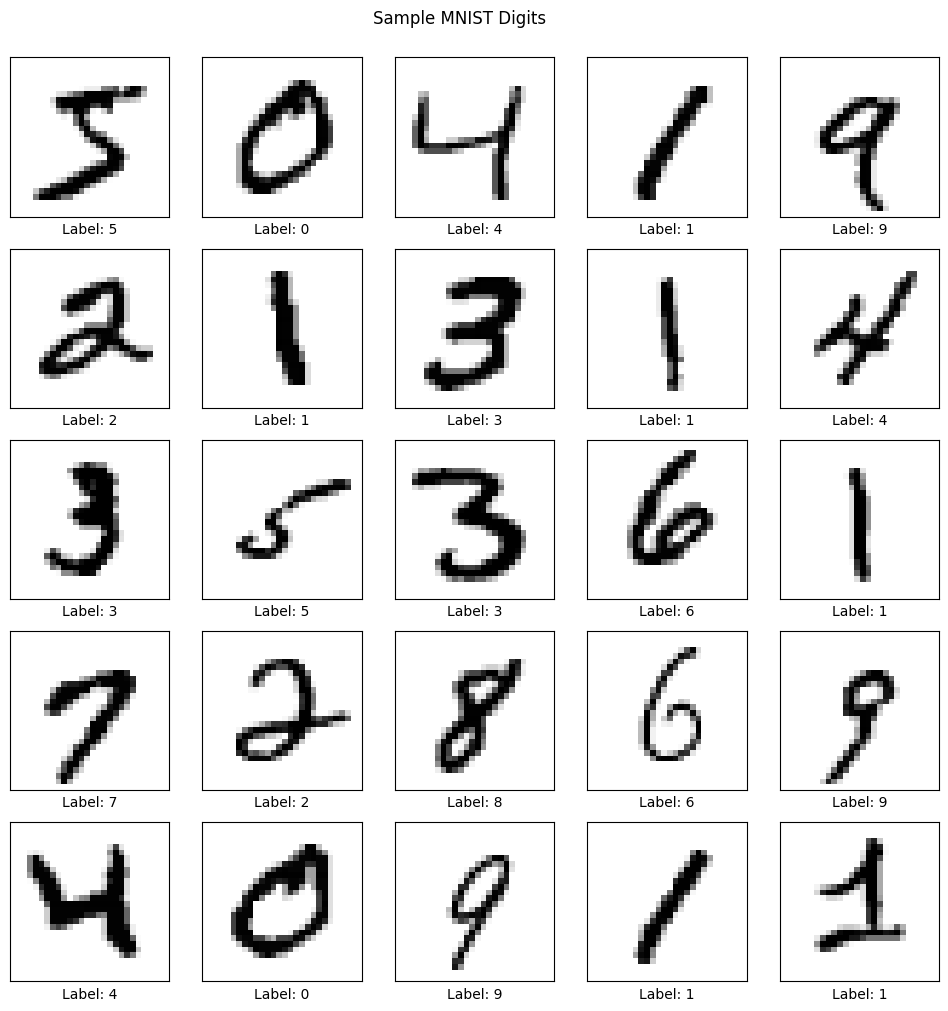

In [ ]:
plt.figure(figsize=(12,12))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(X_train[i], cmap=plt.cm.binary)
    plt.xlabel(f"Label: {y_train[i]}")
plt.suptitle("Sample MNIST Digits", y=0.92)
plt.show()

### Step 3: Build the Neural Network Model

We will construct a simple **Feedforward Neural Network** (also known as a Multi-Layer Perceptron or MLP) using Keras's `Sequential` API. This API allows us to build models layer-by-layer.

In [ ]:
model = Sequential([
    # Flatten layer: Transforms the 2D image (28x28) into a 1D array (28*28 = 784 pixels).
    # This is necessary because Dense layers expect 1D input.
    Flatten(input_shape=(28, 28)),

    # First Dense (hidden) layer: A fully connected layer with 128 neurons.
    # 'relu' (Rectified Linear Unit) is a common activation function for hidden layers.
    Dense(128, activation='relu'),

    # Dropout layer: Randomly sets a fraction of input units to 0 at each update during training time,
    # which helps prevent overfitting.
    Dropout(0.2),

    # Second Dense (hidden) layer: Another fully connected layer with 64 neurons.
    Dense(64, activation='relu'),

    # Output layer: A fully connected layer with 10 neurons (one for each digit 0-9).
    # 'softmax' activation is used for multi-class classification, outputting probabilities for each class.
    Dense(10, activation='softmax')
])

model.summary() # Print a summary of the model's architecture

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### Step 4: Compile the Model

Before training, we need to "compile" the model. This step configures the model for training by specifying the optimizer, loss function, and metrics to monitor.

In [ ]:
model.compile(
    optimizer='adam', # Adam is a popular optimization algorithm
    loss='sparse_categorical_crossentropy', # Suitable for integer labels (0, 1, ..., 9)
    metrics=['accuracy'] # Metric to monitor during training and evaluation
)

print("Model compiled successfully!")

Model compiled successfully!


### Step 5: Train the Model

Now, we train the model using the `fit()` method. This is where the model learns from the training data.

In [ ]:
# Train the model
# epochs: Number of times the model will iterate over the entire training dataset.
# batch_size: Number of samples per gradient update.
# validation_split: Fraction of the training data to be used as validation data.
history = model.fit(
    X_train, y_train,
    epochs=10, # You can experiment with more epochs
    batch_size=32,
    validation_split=0.1, # Use 10% of training data for validation during training
    verbose=1 # Show training progress
)

print("Model training complete!")

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9096 - loss: 0.3015 - val_accuracy: 0.9692 - val_loss: 0.1058
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9577 - loss: 0.1406 - val_accuracy: 0.9727 - val_loss: 0.0959
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9672 - loss: 0.1071 - val_accuracy: 0.9725 - val_loss: 0.0929
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9721 - loss: 0.0888 - val_accuracy: 0.9790 - val_loss: 0.0757
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9750 - loss: 0.0778 - val_accuracy: 0.9770 - val_loss: 0.0801
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9779 - loss: 0.0720 - val_accuracy: 0.9770 - val_loss: 0.0795
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9796 - loss: 0.0637 - val_accuracy: 0.9807 - val_loss: 0.0686
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9811 - loss: 0.0573 - 

#### Plotting Training History

It's good practice to visualize the training and validation accuracy/loss over epochs to check for overfitting or underfitting.

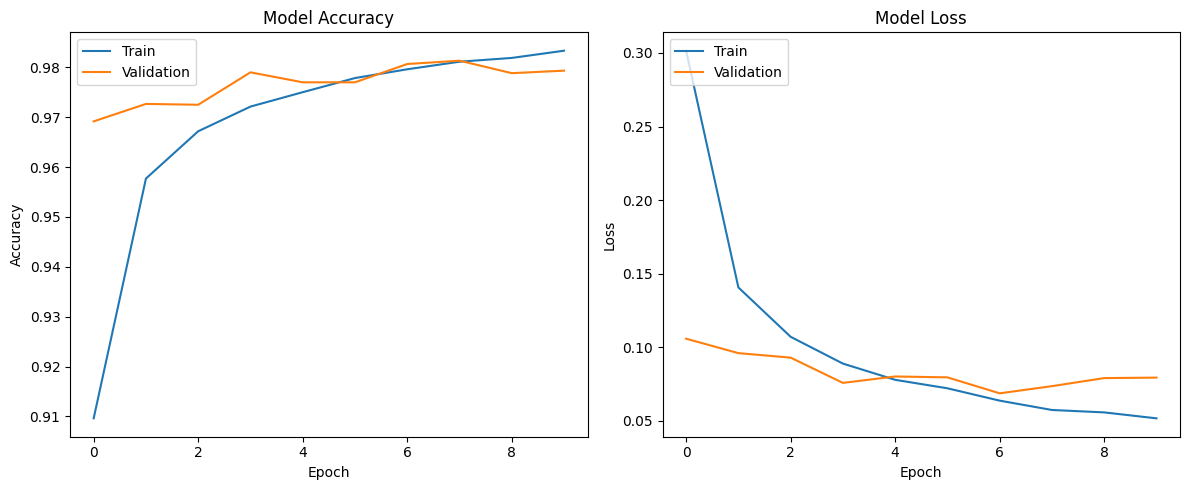

In [ ]:
# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.tight_layout()
plt.show()

### Step 6: Evaluate the Model

After training, we evaluate the model's performance on the completely unseen test dataset to get an unbiased estimate of its generalization capability.

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f}')

313/313 - 1s - 2ms/step - accuracy: 0.9792 - loss: 0.0763
Test Loss: 0.0763
Test Accuracy: 0.9792


#### Detailed Evaluation Metrics

Let's look at the classification report and confusion matrix for a more detailed understanding of the model's performance per class.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.98      1032
           3       0.97      0.98      0.98      1010
           4       0.97      0.98      0.98       982
           5       0.97      0.98      0.97       892
           6       0.99      0.98      0.98       958
           7       0.98      0.98      0.98      1028
           8       0.97      0.97      0.97       974
           9       0.99      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



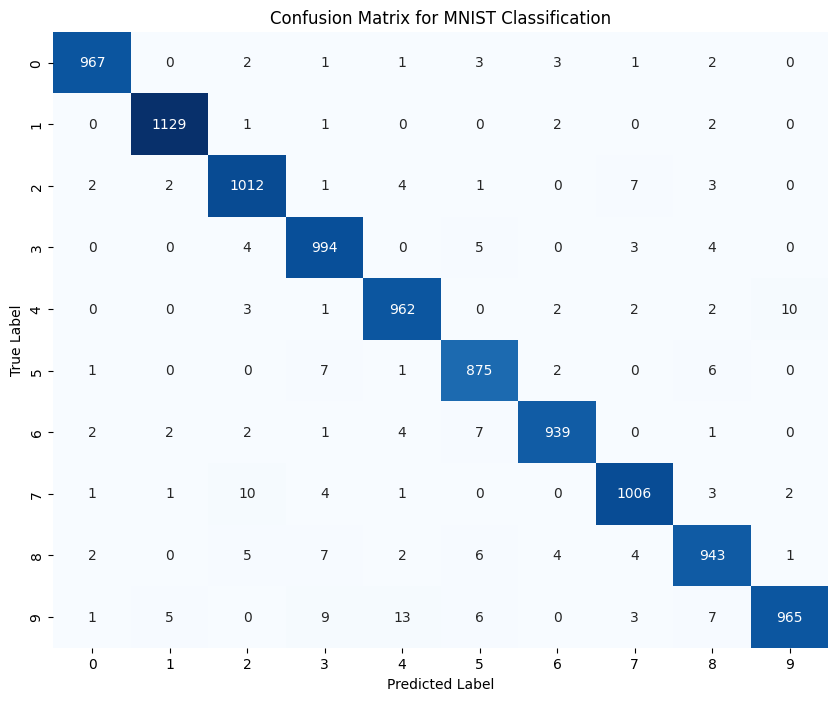

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Get predictions for the test set
y_pred_probs = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1) # Convert probabilities to class labels

print("Classification Report:")
print(classification_report(y_test, y_pred_classes))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for MNIST Classification')
plt.show()

### Step 6.1: Visualizing Misclassified Examples

To understand where our model struggled, let's find and plot some of the images from the test set that our model classified incorrectly. This is a crucial step in real-world error analysis.

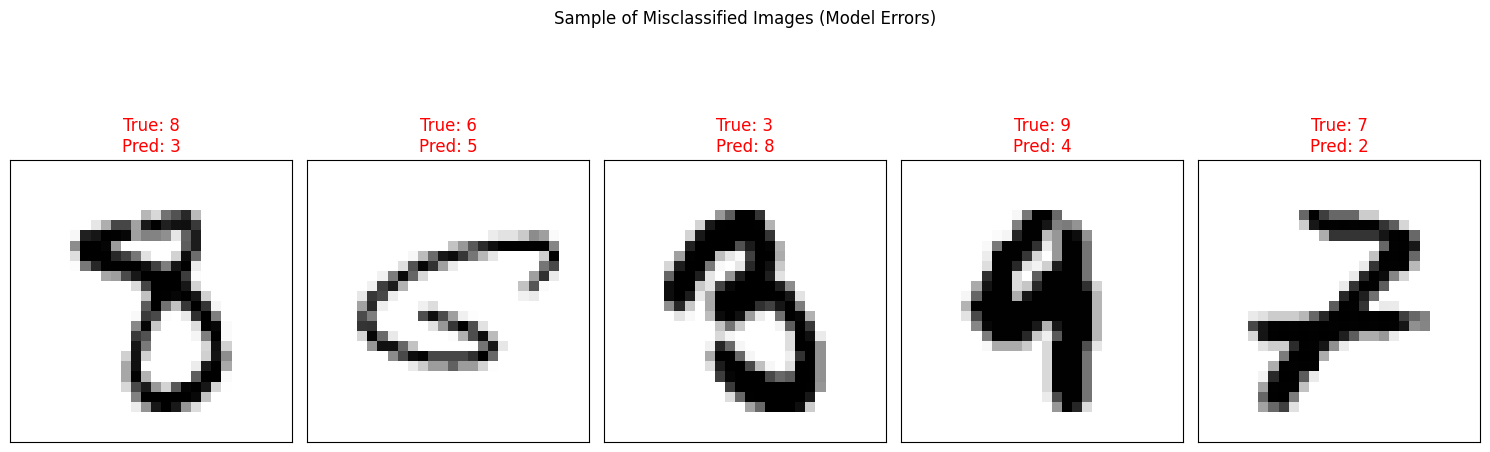

In [ ]:
# Find indices where predicted labels do not match true labels
misclassified_idx = np.where(y_pred_classes != y_test)[0]

# Plot a sample of misclassified images
num_errors = min(len(misclassified_idx), 5)
random_error_indices = np.random.choice(misclassified_idx, num_errors, replace=False)

plt.figure(figsize=(15, 5))
for i, idx in enumerate(random_error_indices):
    img = X_test[idx]
    true_label = y_test[idx]
    pred_label = y_pred_classes[idx]

    plt.subplot(1, num_errors, i + 1)
    plt.imshow(img, cmap=plt.cm.binary)
    plt.xticks([])
    plt.yticks([])
    plt.title(f"True: {true_label}\nPred: {pred_label}", color='red')

plt.suptitle("Sample of Misclassified Images (Model Errors)", y=1.05)
plt.tight_layout()
plt.show()

### Step 7: Make Predictions on Individual Samples

Let's pick a few random images from the test set and see what our trained model predicts.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


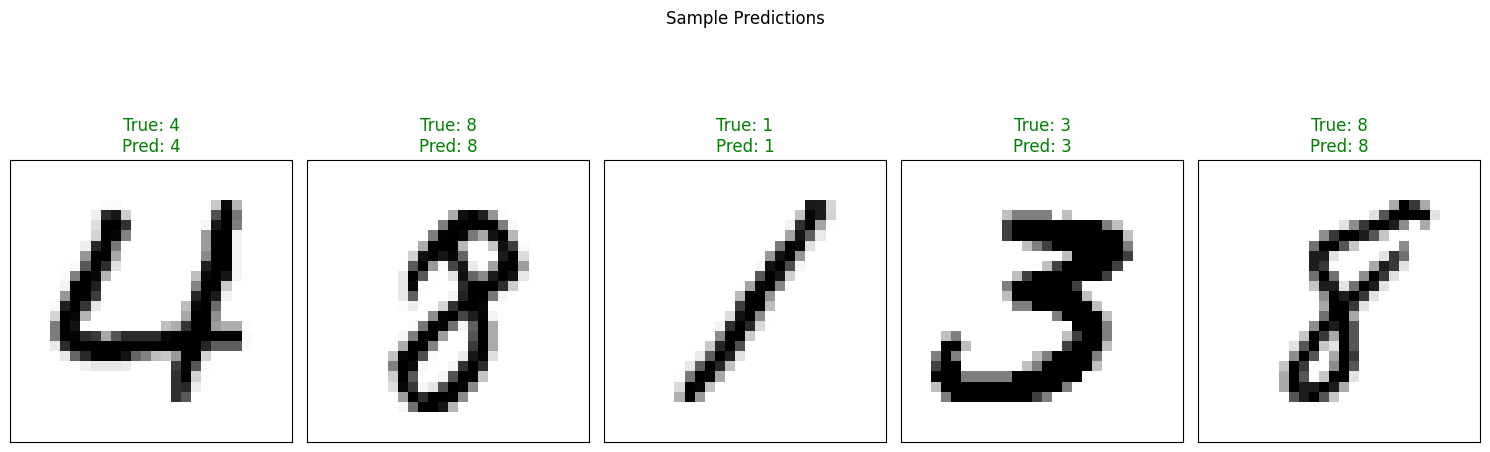

In [ ]:
# Select a few random images from the test set
num_samples = 5
random_indices = np.random.choice(len(X_test), num_samples, replace=False)

plt.figure(figsize=(15, 5))
for i, idx in enumerate(random_indices):
    img = X_test[idx]
    true_label = y_test[idx]
    predicted_prob = model.predict(np.expand_dims(img, axis=0))
    predicted_label = np.argmax(predicted_prob)

    plt.subplot(1, num_samples, i + 1)
    plt.imshow(img, cmap=plt.cm.binary)
    plt.xticks([])
    plt.yticks([])
    plt.title(f"True: {true_label}\nPred: {predicted_label}",
              color=('green' if true_label == predicted_label else 'red'))
plt.suptitle("Sample Predictions", y=1.05)
plt.tight_layout()
plt.show()

### Step 8: Comparing with a Simple Convolutional Neural Network (CNN)

As mentioned in the challenges, Dense layers do not capture spatial hierarchy well (like edges and shapes in 2D space). Let's build a quick CNN to see how it compares to our Multi-Layer Perceptron.

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Reshape data to include the single channel (grayscale channel)
X_train_cnn = np.expand_dims(X_train, axis=-1)
X_test_cnn = np.expand_dims(X_test, axis=-1)

cnn_model = Sequential([
    # Convolutional Layer
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    # Flatten and Dense Layers
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the CNN model for just 3 epochs for speed comparison
cnn_history = cnn_model.fit(
    X_train_cnn, y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

cnn_loss, cnn_acc = cnn_model.evaluate(X_test_cnn, y_test, verbose=0)
print(f"\nMLP Test Accuracy: {test_acc:.4f}")
print(f"CNN Test Accuracy: {cnn_acc:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 28ms/step - accuracy: 0.9371 - loss: 0.2120 - val_accuracy: 0.9778 - val_loss: 0.0838
Epoch 2/3
844/844 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.9791 - loss: 0.0678 - val_accuracy: 0.9865 - val_loss: 0.0529
Epoch 3/3
844/844 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - accuracy: 0.9857 - loss: 0.0464 - val_accuracy: 0.9852 - val_loss: 0.0568

MLP Test Accuracy: 0.9792
CNN Test Accuracy: 0.9815


### Mini-Challenges / Further Exploration

1.  **Experiment with Network Architecture:**
    -   Add more `Dense` layers or change the number of neurons in existing layers. How does this affect training time and accuracy?
    -   Try different activation functions (e.g., `sigmoid`, `tanh`) for the hidden layers. What impact do they have?
2.  **Optimize Training:**
    -   Change the `optimizer` (e.g., `sgd`, `rmsprop`).
    -   Adjust the `epochs` and `batch_size`. Observe the training history plots for signs of overfitting (validation loss increasing while training loss decreases) or underfitting (both losses high).
3.  **Regularization:**
    -   Experiment with the `Dropout` rate. What happens if you set it too high or too low?
    -   Research other regularization techniques like L1/L2 regularization and try to implement them.
4.  **Convolutional Neural Networks (CNNs):** For image data, CNNs are typically much more effective. Research basic CNN layers (`Conv2D`, `MaxPooling2D`) and try to build a simple CNN for the MNIST dataset. Compare its performance to the MLP.